# Task 5: Credit Card Fraud Detection
**MyDailyWork Data Science Internship**

Goal: find the few fraudulent transactions hidden among hundreds of thousands of genuine ones.

## Step 1: Importing the libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix

## Step 2: Reading the dataset

In [8]:
# Read Dataset  (in Google Colab use: "/content/creditcard.csv")
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,69.99,0


In [9]:
df.shape

(284807, 12)

In [10]:
# Missing values (total) and duplicate rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Missing values: 0
Duplicate rows: 1081


## Step 3: The big problem - fraud is very rare

In [11]:
# Class 0 = genuine, Class 1 = fraud
print(df["Class"].value_counts())
print("Fraud is only", round(df["Class"].mean() * 100, 3), "% of all transactions")

Class
0    283253
1       473
Name: count, dtype: int64
Fraud is only 0.167 % of all transactions


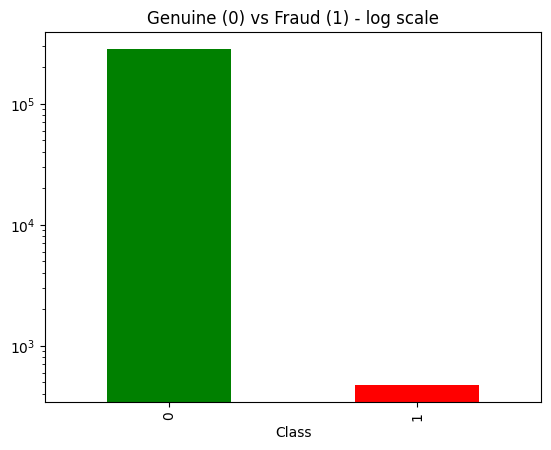

In [12]:
df["Class"].value_counts().plot(kind="bar", color=["green", "red"], logy=True)
plt.title("Genuine (0) vs Fraud (1) - log scale")
plt.show()

In [13]:
# A lazy model that says "genuine" for EVERY transaction:
print("Accuracy of the lazy model:", round((df["Class"] == 0).mean() * 100, 2), "%")
print("Frauds it catches: 0")

Accuracy of the lazy model: 99.83 %
Frauds it catches: 0


So **accuracy is useless here**. We will judge models with **precision** (how many flagged transactions are really fraud)
and **recall** (how many real frauds we catch).

## Step 4: Spliting and scaling the data

In [14]:
x = df.drop("Class", axis=1)    # input features
y = df["Class"]                 # output label

# stratify keeps the same fraud share in train and test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
x_train = x_train.copy()
x_test = x_test.copy()
x_test_raw = x_test.copy()     # keep an unscaled copy for the app demo file

In [15]:
# Time and Amount have big numbers, so scale them (V1 to V28 are already scaled)
scaler = StandardScaler()
x_train[["Time", "Amount"]] = scaler.fit_transform(x_train[["Time", "Amount"]])
x_test[["Time", "Amount"]] = scaler.transform(x_test[["Time", "Amount"]])

## Step 5: Fixing the imbalance (training data only!)
Never change the test data. It must look like real life.

In [16]:
train_data = x_train.copy()
train_data["Class"] = y_train
fraud = train_data[train_data["Class"] == 1]
normal = train_data[train_data["Class"] == 0]

# Undersampling: keep ALL frauds and the same number of genuine transactions
under = pd.concat([fraud, normal.sample(len(fraud), random_state=42)])
x_under = under.drop("Class", axis=1)
y_under = under["Class"]

# Oversampling: copy the frauds again and again until they match the genuine ones
over = pd.concat([normal, fraud.sample(len(normal), replace=True, random_state=42)])
x_over = over.drop("Class", axis=1)
y_over = over["Class"]

print("Original:", len(x_train), "| Undersampled:", len(x_under), "| Oversampled:", len(x_over))

Original: 226980 | Undersampled: 756 | Oversampled: 453204


## Step 6: Training the models and comparing them

In [17]:
results = []
trained = {}

def evaluate(name, model, x_tr, y_tr):
    model.fit(x_tr, y_tr)
    y_pred = model.predict(x_test)
    trained[name] = model
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 3),
        "Recall": round(recall_score(y_test, y_pred), 3),
        "F1": round(f1_score(y_test, y_pred), 3),
    })

evaluate("Logistic Regression (plain)", LogisticRegression(max_iter=1000), x_train, y_train)
evaluate("Logistic Regression (class weights)", LogisticRegression(max_iter=1000, class_weight="balanced"), x_train, y_train)
evaluate("Logistic Regression + Undersampling", LogisticRegression(max_iter=1000), x_under, y_under)
evaluate("Logistic Regression + Oversampling", LogisticRegression(max_iter=1000), x_over, y_over)
evaluate("Random Forest + Undersampling", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), x_under, y_under)
evaluate("Random Forest (class weights)", RandomForestClassifier(n_estimators=50, max_depth=10, class_weight="balanced_subsample", random_state=42, n_jobs=-1), x_train, y_train)

results_df = pd.DataFrame(results).set_index("Model")
results_df

,Precision,Recall,F1
Model,,,
Logistic Regression (plain),0.783,0.379,0.511
Logistic Regression (class weights),0.030,0.863,0.057
Logistic Regression + Undersampling,0.030,0.863,0.058
Logistic Regression + Oversampling,0.030,0.863,0.057
Random Forest + Undersampling,0.037,0.842,0.071
Random Forest (class weights),0.667,0.653,0.660


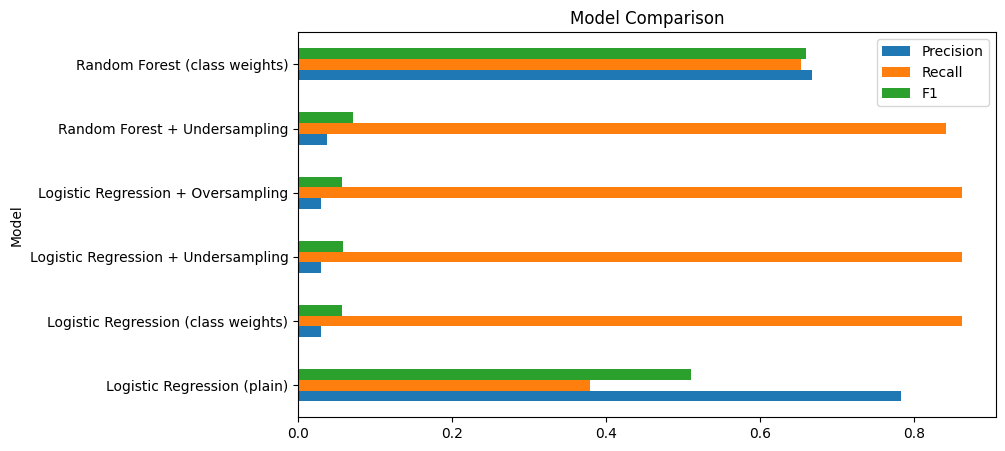

In [18]:
results_df[["Precision", "Recall", "F1"]].plot(kind="barh", figsize=(9, 5))
plt.title("Model Comparison")
plt.show()

## Step 7: Checking for the best model

In [19]:
best_name = results_df["F1"].idxmax()
model = trained[best_name]
y_pred = model.predict(x_test)

print("Best model:", best_name)
print(classification_report(y_test, y_pred, target_names=["Genuine", "Fraud"]))

Best model: Random Forest (class weights)
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56651
       Fraud       0.67      0.65      0.66        95

    accuracy                           1.00     56746
   macro avg       0.83      0.83      0.83     56746
weighted avg       1.00      1.00      1.00     56746



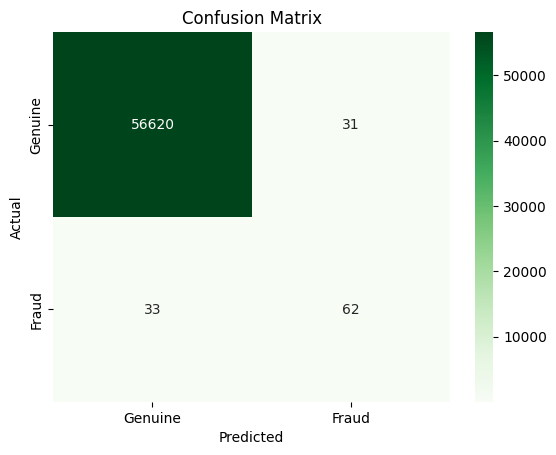

In [20]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=["Genuine", "Fraud"], yticklabels=["Genuine", "Fraud"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**How to read it:** bottom-right = frauds caught, bottom-left = frauds missed, top-right = genuine transactions wrongly flagged.

## Step 8: Saving the model

In [21]:
joblib.dump({
    "model": model, "scaler": scaler,
    "features": list(x.columns), "model_name": best_name,
}, "fraud_model.pkl")

# Demo file: 30 frauds + 270 genuine transactions from the test data
demo = x_test_raw.copy()
demo["Class"] = y_test
demo = pd.concat([demo[demo["Class"] == 1].head(30), demo[demo["Class"] == 0].sample(270, random_state=42)])
demo = demo.sample(frac=1, random_state=42)
demo.to_csv("demo_transactions.csv", index=False)
print("Saved fraud_model.pkl and demo_transactions.csv")

Saved fraud_model.pkl and demo_transactions.csv
